# Rolling Stones Song Cohorts
**Machine Learning Unit End Project 2 · Spotify recommendation analysis**

Which albums contain the most popular tracks in this catalog snapshot, and what kinds of songs group together based on their audio features?

**Run the notebook.** Keep `rolling_stones_spotify.csv` beside this notebook. In a Python environment, install the dependencies with `python -m pip install -r requirements.txt`. Open the notebook in Jupyter and select **Restart Kernel and Run All Cells**. The saved notebook contains the figures and results.

## 1. Inspect and clean the catalog

The unit of analysis is a Spotify track ID. Different recordings or releases can share a title, so title alone cannot identify duplicates. Check for missing or blank values, exact duplicate records, duplicate IDs, invalid dates, out-of-range measurements, and mismatched IDs and URIs. The exported row index has no musical meaning.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 123
sns.set_theme(style="whitegrid", palette="colorblind")

raw = pd.read_csv("rolling_stones_spotify.csv")
print(f"Source catalog: {len(raw):,} rows × {raw.shape[1]} columns")
display(raw[["name", "album", "release_date", "id", "popularity"]].head())

data = raw.drop(columns="Unnamed: 0").copy()
missing = data.isna().sum()
blank = data.select_dtypes(exclude="number").apply(lambda s: s.str.strip().eq("").sum())
display(pd.DataFrame({"Missing": missing, "Blank text": blank.reindex(missing.index, fill_value=0)}))

bounded = ["acousticness", "danceability", "energy", "instrumentalness",
           "liveness", "speechiness", "valence"]
dates = pd.to_datetime(data["release_date"], errors="coerce")
checks = {
    "Exact duplicate rows": data.duplicated().sum(),
    "Duplicate Spotify IDs": data["id"].duplicated().sum(),
    "Unparseable release dates": dates.isna().sum(),
    "Invalid ID or mismatched URI": (
        ~data["id"].str.fullmatch(r"[A-Za-z0-9]{22}") |
        data["uri"].ne("spotify:track:" + data["id"])
    ).sum(),
    "Rows with bounded audio scores outside [0, 1]": (
        ~data[bounded].apply(lambda s: s.between(0, 1)).all(axis=1)
    ).sum(),
    "Popularity outside [0, 100]": (~data["popularity"].between(0, 100)).sum(),
    "Loudness outside [-60, 0] dB": (~data["loudness"].between(-60, 0)).sum(),
    "Nonpositive tempo, duration, or track number": (
        data[["tempo", "duration_ms", "track_number"]].le(0).any(axis=1)
    ).sum(),
}
display(pd.Series(checks, name="Records flagged").to_frame())
assert not (sum(checks.values()) + missing.sum() + blank.sum()), "Review flagged records."

# Exclude standalone concert introductions while preserving songs with an intro.
intro_pattern = (
    r"^(?:Concert Intro Music|Band Introductions?|Band Intros|Whoopi Goldberg Intro|"
    r"Show Intro|Charlie's Intro To|Intro(?=\s*-|\s*\(|:)|Introduction(?=\s*-))"
)
intro = data["name"].str.contains(intro_pattern, case=False, regex=True)
display(data.loc[intro, ["name", "album", "popularity"]].reset_index(drop=True))
songs = data.loc[~intro].copy()
songs["release_year"] = dates.loc[songs.index].dt.year
songs["release_decade"] = songs["release_year"].floordiv(10).mul(10)
songs["duration_min"] = songs["duration_ms"] / 60_000
songs["log_duration"] = np.log1p(songs["duration_min"])
print(f"Excluded {intro.sum()} standalone intro tracks. Retained {len(songs):,} song records.")

audio = bounded + ["loudness", "tempo", "duration_min"]
quartiles = songs[audio].quantile([.25, .75])
iqr = quartiles.loc[.75] - quartiles.loc[.25]
outside = songs[audio].lt(quartiles.loc[.25] - 1.5 * iqr) | songs[audio].gt(
    quartiles.loc[.75] + 1.5 * iqr
)
quality = songs[audio].describe().T[["min", "25%", "50%", "75%", "max"]]
quality["IQR flags"] = outside.sum()
display(quality.round(3))
display(songs.nlargest(3, "duration_min")[["name", "album", "duration_min"]].round(2))

Source catalog: 1,610 rows × 18 columns


,name,album,release_date,id,popularity
0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,2IEkywLJ4ykbhi1yRQvmsT,33
1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,6GVgVJBKkGJoRfarYRvGTU,34
2,Start Me Up - Live,Licked Live In NYC,2022-06-10,1Lu761pZ0dBTGpzxaQoZNW,34
3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,1agTQzOTUnGNggyckEqiDH,32
4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,7piGJR8YndQBQWVXv6KtQw,32


,Missing,Blank text
name,0,0
album,0,0
release_date,0,0
track_number,0,0
id,0,0
uri,0,0
acousticness,0,0
danceability,0,0
energy,0,0
instrumentalness,0,0


,Records flagged
Exact duplicate rows,0
Duplicate Spotify IDs,0
Unparseable release dates,0
Invalid ID or mismatched URI,0
"Rows with bounded audio scores outside [0, 1]",0
"Popularity outside [0, 100]",0
"Loudness outside [-60, 0] dB",0
"Nonpositive tempo, duration, or track number",0


,name,album,popularity
0,Concert Intro Music - Live,Licked Live In NYC,33
1,Band Introductions - Live,Licked Live In NYC,27
2,Band Introductions - Live at Wembley Stadium 1982,Tattoo You (Super Deluxe),15
3,Intro - Live,A Bigger Bang (Live),17
4,Band Intros - Live,A Bigger Bang (Live),13
5,Whoopi Goldberg Intro - Live,Voodoo Lounge Uncut (Live),12
6,Whoopi Goldberg Intro - Live,Voodoo Lounge Uncut (Live),10
7,Intro - Live,Ladies & Gentlemen (Live),17
8,Show Intro - Live,Live 1965: Music From Charlie Is My Darling (L...,0
9,Charlie's Intro To Little Red Rooster - Live,Live 1965: Music From Charlie Is My Darling (L...,11


Excluded 15 standalone intro tracks. Retained 1,595 song records.


,min,25%,50%,75%,max,IQR flags
acousticness,0.000,0.058,0.181,0.400,0.994,4
danceability,0.104,0.364,0.459,0.579,0.887,0
energy,0.141,0.674,0.844,0.945,0.997,8
instrumentalness,0.000,0.000,0.014,0.175,0.978,267
liveness,0.022,0.153,0.371,0.892,0.998,0
speechiness,0.023,0.036,0.051,0.085,0.330,88
valence,0.037,0.410,0.585,0.780,0.974,0
loudness,-24.408,-8.953,-6.493,-4.600,-1.014,13
tempo,57.772,107.532,124.742,142.460,216.304,33
duration_min,0.462,3.185,4.072,4.938,16.364,71


,name,album,duration_min
220,Miss You - Live,Bridges To Bremen (Live),16.36
460,Midnight Rambler - Live,Havana Moon (Live),15.49
537,Miss You - Live,Totally Stripped - Paris (Live),15.12


The integrity checks found no missing values, duplicate IDs, or invalid ranges. Standalone intro tracks were excluded by title because the recommendation task targets songs. The IQR rule flags statistical extremes for inspection. Long tracks and unusually quiet recordings can be legitimate, so plausible extremes are retained. Log duration reduces the influence of exceptionally long recordings in distance calculations. Release year and decade come from the catalog's album dates, which can reflect a reissue rather than the original recording year.

## 2. Recommend two albums by popular-track count

This analysis defines a popular track as a Spotify popularity score of **40 or higher**, which isolates the upper end of this catalog snapshot. Rank by the number of distinct qualifying track IDs on each album. For tied counts, prefer the higher share of qualifying tracks, then sort alphabetically. Shares provide context because larger albums have more opportunities to accumulate qualifying tracks.

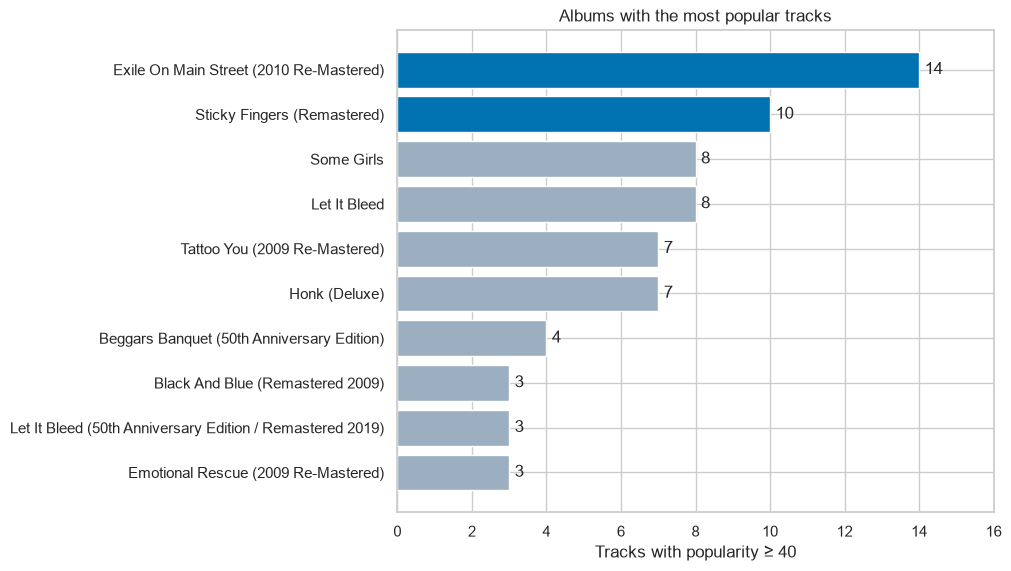

,album,tracks,popular_tracks,popular_share
0,Exile On Main Street (2010 Re-Mastered),18,14,77.8%
1,Sticky Fingers (Remastered),10,10,100.0%
2,Some Girls,10,8,80.0%
3,Let It Bleed,18,8,44.4%
4,Tattoo You (2009 Re-Mastered),11,7,63.6%
5,Honk (Deluxe),47,7,14.9%
6,Beggars Banquet (50th Anniversary Edition),10,4,40.0%
7,Black And Blue (Remastered 2009),8,3,37.5%
8,Let It Bleed (50th Anniversary Edition / Remastered 2019),9,3,33.3%
9,Emotional Rescue (2009 Re-Mastered),10,3,30.0%


**Recommended albums:** **Exile On Main Street (2010 Re-Mastered)** (14 qualifying tracks) and **Sticky Fingers (Remastered)** (10 qualifying tracks). The cutoff includes 7.5% of song records.

,cutoff,rank,album,popular_tracks,tracks
0,40,1,Exile On Main Street (2010 Re-Mastered),14,18
1,40,2,Sticky Fingers (Remastered),10,10
2,40,3,Some Girls,8,10
3,50,1,Sticky Fingers (Remastered),6,10
4,50,2,Exile On Main Street (2010 Re-Mastered),4,18
5,50,3,Let It Bleed,4,18
6,60,1,Sticky Fingers (Remastered),3,10
7,60,2,Some Girls,2,10
8,60,3,Aftermath,2,11


In [2]:
def album_ranking(threshold):
    return (songs.assign(is_popular=songs["popularity"].ge(threshold))
            .groupby("album", as_index=False)
            .agg(tracks=("id", "nunique"), popular_tracks=("is_popular", "sum"))
            .assign(popular_share=lambda d: d["popular_tracks"] / d["tracks"])
            .sort_values(["popular_tracks", "popular_share", "album"],
                         ascending=[False, False, True], ignore_index=True))

ranking = album_ranking(40)
top = ranking.head(10)
fig, ax = plt.subplots(figsize=(10, 5.6), layout="constrained")
bars = ax.barh(top["album"], top["popular_tracks"],
               color=["#0072B2" if i < 2 else "#9CAFC0" for i in range(len(top))])
ax.bar_label(bars, padding=4)
ax.set(xlabel="Tracks with popularity ≥ 40", title="Albums with the most popular tracks")
ax.set_xlim(0, top["popular_tracks"].max() + 2)
ax.invert_yaxis()
plt.show()

display(top.style.format({"popular_share": "{:.1%}"}))
display(Markdown(
    f"**Recommended albums:** **{ranking.loc[0, 'album']}** "
    f"({ranking.loc[0, 'popular_tracks']} qualifying tracks) and "
    f"**{ranking.loc[1, 'album']}** ({ranking.loc[1, 'popular_tracks']} qualifying tracks). "
    f"The cutoff includes {ranking['popular_tracks'].sum() / len(songs):.1%} of song records."
))
sensitivity = pd.concat([
    album_ranking(cutoff).head(3).assign(cutoff=cutoff, rank=range(1, 4))
    for cutoff in (40, 50, 60)
], ignore_index=True)
display(sensitivity[["cutoff", "rank", "album", "popular_tracks", "tracks"]])

The sensitivity table shows how the recommendations change when “popular” means a score of at least 50 or 60. The count-based result reflects the chosen cutoff and treats each catalog edition as a distinct album.

## 3. Explore the audio features and popularity

Compare distributions and use Spearman rank correlations to look for monotonic relationships. Compare popularity correlations within album-release decades. All popularity values come from a single supplied snapshot, so the decade comparison describes differences between release groups and cannot show changes in the same track's popularity over time.

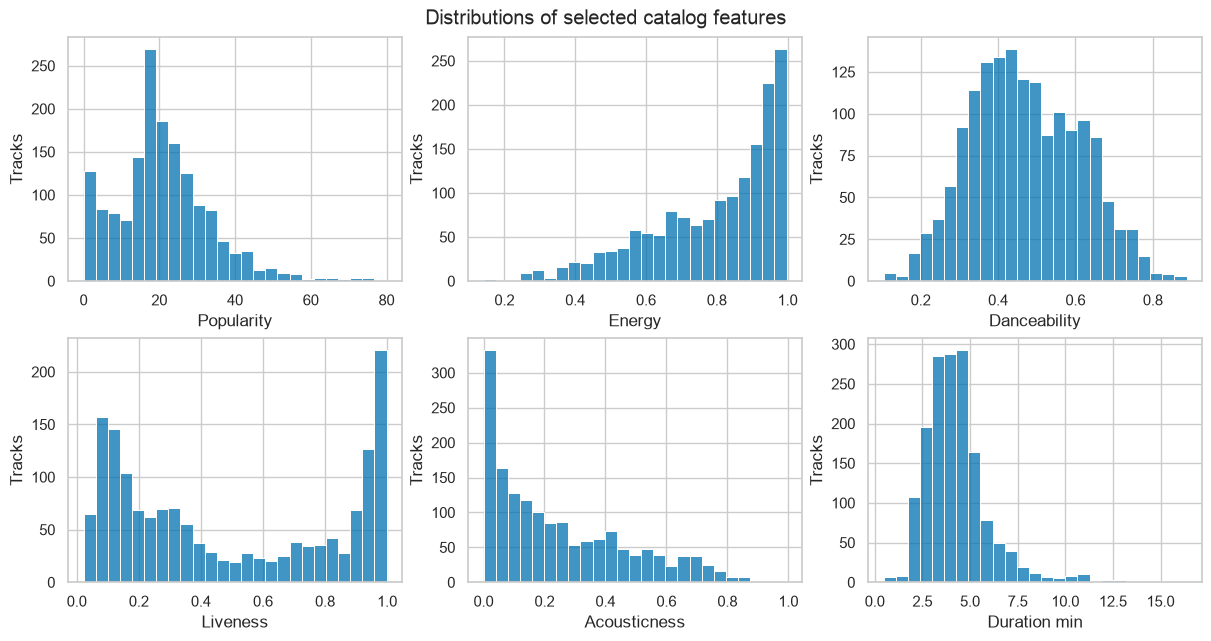

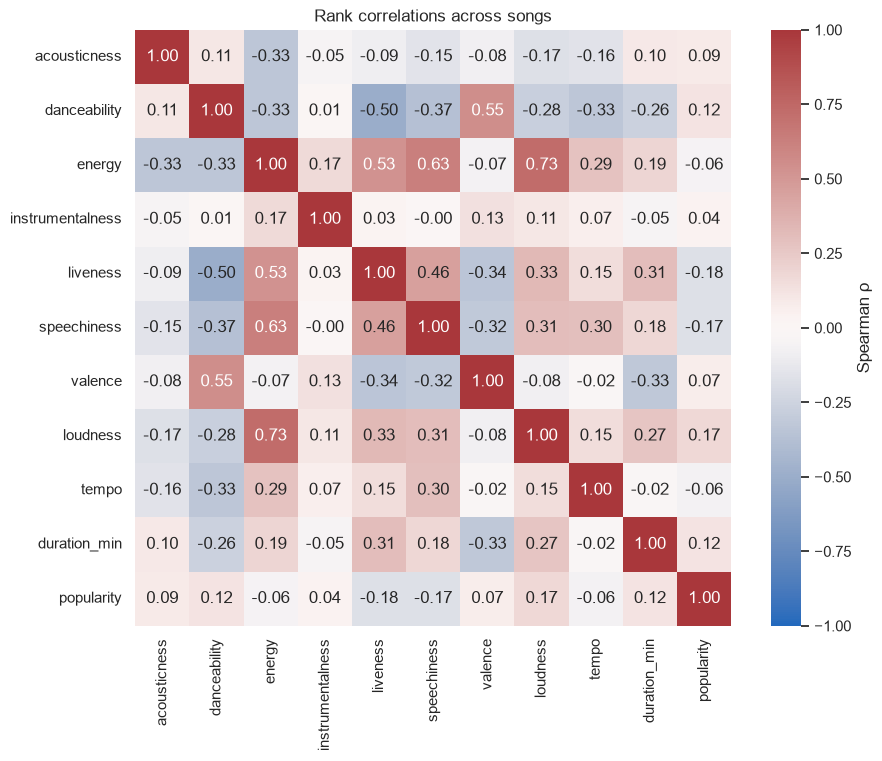

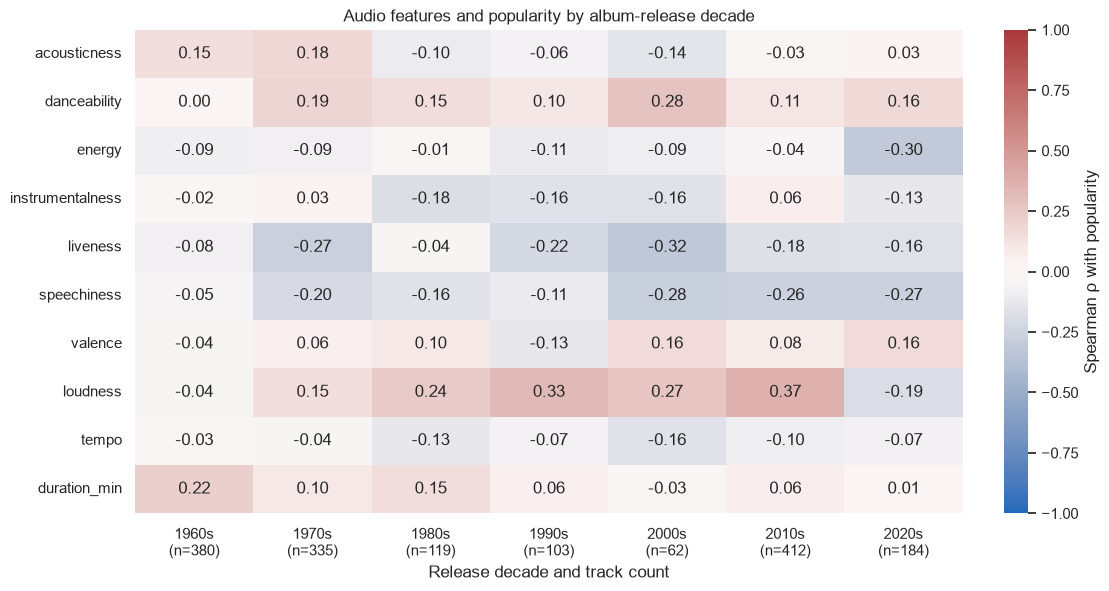

The largest absolute correlations with popularity overall were liveness (-0.18), speechiness (-0.17), loudness (+0.17). **Loudness** showed the largest spread across decades, from -0.19 in the 2020s to +0.37 in the 2010s. Each decade combines a different mix of albums, releases, and recordings.

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.3), layout="constrained")
for ax, feature in zip(axes.flat, ["popularity", "energy", "danceability",
                                 "liveness", "acousticness", "duration_min"]):
    sns.histplot(songs[feature], bins=25, ax=ax, color="#0072B2")
    ax.set(xlabel=feature.replace("_", " ").capitalize(), ylabel="Tracks")
fig.suptitle("Distributions of selected catalog features")
plt.show()

corr = songs[audio + ["popularity"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 7.5), layout="constrained")
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f",
            square=True, cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title("Rank correlations across songs")
plt.show()

decades = songs.groupby("release_decade")
sizes = decades.size()
decade_corr = pd.DataFrame({
    decade: group[audio + ["popularity"]].corr(method="spearman").loc[audio, "popularity"]
    for decade, group in decades
})
fig, ax = plt.subplots(figsize=(11, 5.8), layout="constrained")
sns.heatmap(decade_corr, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f",
            cbar_kws={"label": "Spearman ρ with popularity"}, ax=ax)
ax.set(title="Audio features and popularity by album-release decade",
       xlabel="Release decade and track count", ylabel="")
ax.set_xticklabels([f"{year}s\n(n={sizes[year]})" for year in decade_corr], rotation=0)
plt.show()

overall = corr.loc[audio, "popularity"]
strong = overall.abs().nlargest(3).index
strong_text = ", ".join(f"{feature.replace('_', ' ')} ({overall[feature]:+.2f})" for feature in strong)
changing = decade_corr.max(axis=1).sub(decade_corr.min(axis=1)).idxmax()
low, high = decade_corr.loc[changing].idxmin(), decade_corr.loc[changing].idxmax()
display(Markdown(
    f"The largest absolute correlations with popularity overall were {strong_text}. "
    f"**{changing.replace('_', ' ').capitalize()}** showed the largest spread across decades, "
    f"from {decade_corr.loc[changing, low]:+.2f} in the {low}s "
    f"to {decade_corr.loc[changing, high]:+.2f} in the {high}s. "
    "Each decade combines a different mix of albums, releases, and recordings."
))

The liveness distribution has concentrations at both ends, consistent with a catalog containing studio and live material. Energy is concentrated toward the high end, while duration has a long right tail. Energy and loudness move together (Spearman ρ = +0.73), but the strongest audio correlations with popularity are weak in the full catalog (absolute ρ ≤ 0.18). Audio similarity and popularity therefore answer different recommendation questions.

## 4. Reduce dimensions with PCA

Standardize the audio inputs so differences in units such as BPM and dB do not dominate distance. The model uses log duration in place of raw duration. Exclude popularity, release dates, track number, titles, and identifiers from clustering so cohorts reflect audio similarity. PCA summarizes correlated audio features in orthogonal components. Use it to diagnose redundancy and visualize the clusters. The clustering comparison uses the full standardized feature space to preserve distinctions that a two-axis plot could hide.

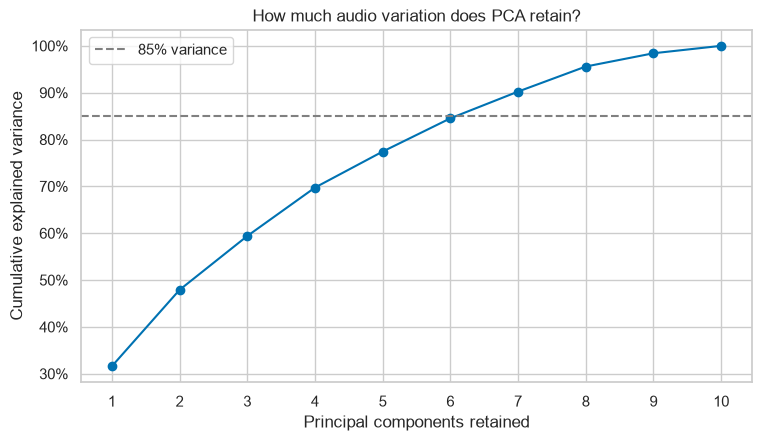

,PC1,PC2
acousticness,-0.167,-0.432
danceability,-0.398,0.249
energy,0.421,0.419
instrumentalness,-0.008,0.242
liveness,0.428,-0.085
speechiness,0.376,-0.078
valence,-0.259,0.570
loudness,0.372,0.303
tempo,0.204,0.112
log_duration,0.255,-0.273


PC1 and PC2 together retain **47.9%** of standardized audio variance. Reaching 85% requires **7 of 10** components. The largest absolute weights are liveness, energy, danceability on PC1 and valence, acousticness, energy on PC2. The two-axis view reveals broad structure while omitting variation on later axes.

In [4]:
features = bounded + ["loudness", "tempo", "log_duration"]
scaled = StandardScaler().fit_transform(songs[features])
pca = PCA()
coordinates = pca.fit_transform(scaled)
cumulative = pca.explained_variance_ratio_.cumsum()
n_85 = int(np.searchsorted(cumulative, .85) + 1)

fig, ax = plt.subplots(figsize=(7.5, 4.3), layout="constrained")
ax.plot(range(1, len(features) + 1), cumulative, "o-", color="#0072B2")
ax.axhline(.85, linestyle="--", color="gray", label="85% variance")
ax.set(xlabel="Principal components retained", ylabel="Cumulative explained variance",
       title="How much audio variation does PCA retain?", xticks=range(1, len(features) + 1))
ax.yaxis.set_major_formatter(lambda value, pos: f"{value:.0%}")
ax.legend()
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"])
display(loadings.round(3))
leaders = [", ".join(loadings[col].abs().nlargest(3).index) for col in loadings]
display(Markdown(
    f"PC1 and PC2 together retain **{cumulative[1]:.1%}** of standardized audio variance. "
    f"Reaching 85% requires **{n_85} of {len(features)}** components. "
    f"The largest absolute weights are {leaders[0]} on PC1 and {leaders[1]} on PC2. "
    "The two-axis view reveals broad structure while omitting variation on later axes."
))

## 5. Compare clustering algorithms and choose the number of cohorts

Compare K-means and Ward agglomerative clustering for 2 through 10 clusters. K-means fits centroids by minimizing within-cluster squared distances. Ward builds a hierarchy by repeatedly merging the groups that cause the smallest increase in within-group variance. Both use Euclidean geometry on the same standardized features. Higher silhouette indicates better separation relative to within-cluster cohesion. Select the highest silhouette among solutions whose smallest cohort contains at least 5% of tracks, a practical cutoff for broad recommendation cohorts.

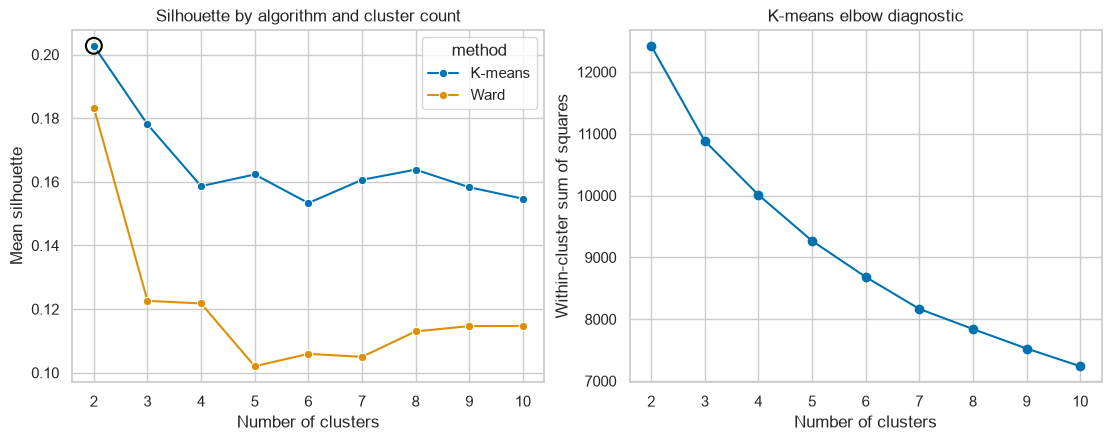

,method,k,silhouette,smallest_share
0,K-means,2,0.203,43.3%
1,Ward,2,0.183,32.1%
2,K-means,3,0.178,26.2%
3,Ward,3,0.123,27.2%
4,K-means,4,0.159,16.9%
5,Ward,4,0.122,8.5%
6,K-means,5,0.162,11.3%
7,Ward,5,0.102,8.5%
8,K-means,6,0.153,9.5%
9,Ward,6,0.106,8.5%


**Selected: K-means with 2 clusters.** Mean silhouette was **0.203** and the smallest group contained **43.3%** of tracks. Silhouette is an internal measure of cluster structure. A score near 0.20 suggests broad groups with substantial overlap. Listener behavior would be needed to test recommendation quality.

In [5]:
trials = []
labels_by_trial = {}
for k in range(2, 11):
    candidates = {
        "K-means": KMeans(n_clusters=k, n_init=20, random_state=SEED),
        "Ward": AgglomerativeClustering(n_clusters=k, linkage="ward"),
    }
    for method, model in candidates.items():
        labels = model.fit_predict(scaled)
        labels_by_trial[method, k] = labels
        trials.append({
            "method": method, "k": k,
            "silhouette": silhouette_score(scaled, labels),
            "smallest_share": np.bincount(labels).min() / len(labels),
            "inertia": model.inertia_ if method == "K-means" else np.nan,
        })

results = pd.DataFrame(trials)
best = results.query("smallest_share >= .05").sort_values(
    ["silhouette", "k", "method"], ascending=[False, True, True]
).iloc[0]
method, k = best["method"], int(best["k"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
sns.lineplot(data=results, x="k", y="silhouette", hue="method", marker="o", ax=axes[0])
axes[0].scatter(k, best["silhouette"], s=130, facecolors="none", edgecolors="black",
                linewidths=1.5, zorder=5)
axes[0].set(title="Silhouette by algorithm and cluster count", ylabel="Mean silhouette")
km_results = results.query("method == 'K-means'")
axes[1].plot(km_results["k"], km_results["inertia"], "o-", color="#0072B2")
axes[1].set(title="K-means elbow diagnostic", ylabel="Within-cluster sum of squares")
for ax in axes:
    ax.set(xlabel="Number of clusters", xticks=range(2, 11))
plt.show()

display(results.drop(columns="inertia").style.format(
    {"silhouette": "{:.3f}", "smallest_share": "{:.1%}"}
))
display(Markdown(
    f"**Selected: {method} with {k} clusters.** Mean silhouette was "
    f"**{best['silhouette']:.3f}** and the smallest group contained "
    f"**{best['smallest_share']:.1%}** of tracks. Silhouette is an internal measure "
    "of cluster structure. A score near 0.20 suggests broad groups with substantial overlap. Listener behavior would be needed to test recommendation quality."
))

## 6. Define the cohorts and find representative songs

Order cohorts by average liveness for readable IDs. Describe each group using its strongest standardized feature differences from the catalog average. The profiles table shows measurements in original units. Examples are the songs nearest to each group's centroid in the full standardized space, with one example per distinct title.

,tracks,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,loudness,tempo,duration_min,popularity
cohort,,,,,,,,,,,,
1,905,0.29,0.54,0.70,0.17,0.26,0.05,0.66,-8.18,119.07,3.81,22.65
2,690,0.19,0.37,0.92,0.15,0.79,0.10,0.48,-5.30,135.89,5.00,18.51


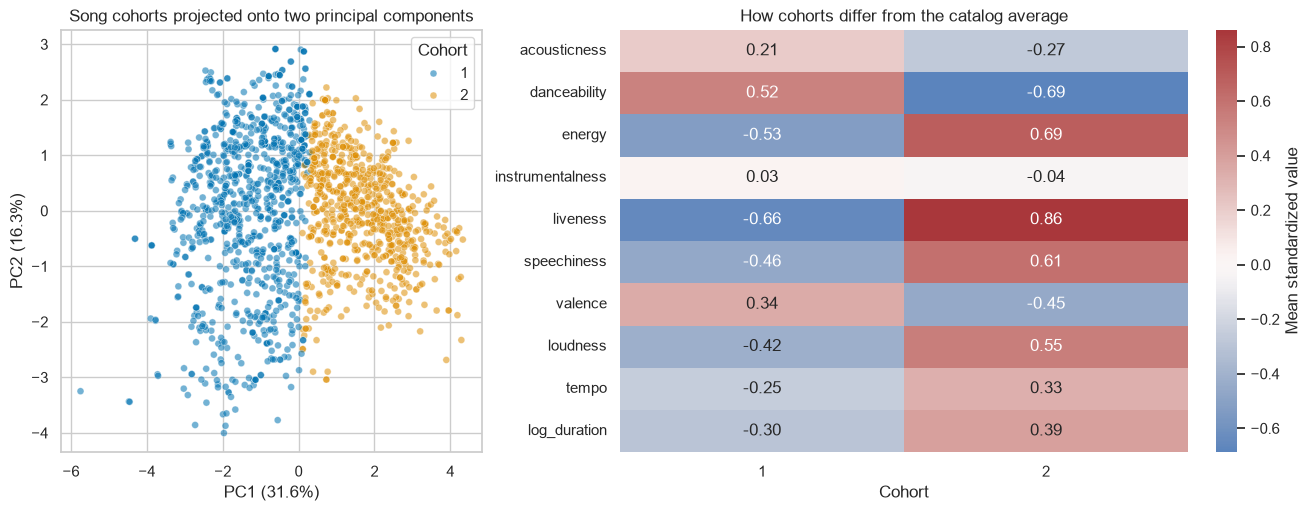

- **Cohort 1 · 905 tracks.** These tracks have lower liveness, lower energy, higher danceability compared with the catalog average. Examples include Who's Been Sleeping Here? (Between The Buttons) · Casino Boogie (Exile On Main Street (Deluxe Version)) · Doo Doo Doo Doo Doo (Heartbreaker) (Goats Head Soup (Deluxe)).
- **Cohort 2 · 690 tracks.** These tracks have higher liveness, higher energy, lower danceability compared with the catalog average. Examples include Live With Me - Live At University Of Leeds / 1971 (Sticky Fingers (Super Deluxe)) · Doo Doo Doo Doo Doo (Heartbreaker) - Live / Forest National Arena, Brussels / 17/10/73 (Goats Head Soup (Deluxe)) · Start Me Up - Live (Sticky Fingers Live At The Fonda Theatre).

Exported 1,595 track assignments to rolling_stones_song_cohorts.csv.


In [6]:
labels = labels_by_trial[method, k]
ordered = songs.assign(label=labels).groupby("label")["liveness"].mean().sort_values()
id_map = {label: i for i, label in enumerate(ordered.index, start=1)}
songs["cohort"] = pd.Series(labels, index=songs.index).map(id_map)
cohorts = songs["cohort"].astype(str)
profile = songs.groupby("cohort")[audio + ["popularity"]].mean()
profile.insert(0, "tracks", songs.groupby("cohort").size())
display(profile.round(2))

z_profiles = pd.DataFrame(scaled, columns=features, index=songs.index).groupby(
    songs["cohort"]
).mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1.35]})
sns.scatterplot(x=coordinates[:, 0], y=coordinates[:, 1], hue=cohorts, hue_order=sorted(cohorts.unique()),
                alpha=.55, s=25, ax=axes[0])
axes[0].set(title="Song cohorts projected onto two principal components",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[0].legend(title="Cohort")
sns.heatmap(z_profiles.T, center=0, cmap="vlag", annot=True, fmt=".2f", ax=axes[1],
            cbar_kws={"label": "Mean standardized value"})
axes[1].set(title="How cohorts differ from the catalog average", xlabel="Cohort")
axes[1].tick_params(axis="y", labelrotation=0)
plt.show()

notes = []
cohort_names = {}
for group_id, row in z_profiles.iterrows():
    strongest = row.abs().nlargest(3).index
    description = ", ".join(
        f"{'higher' if row[f] > 0 else 'lower'} {f.replace('_', ' ')}" for f in strongest
    )
    cohort_names[group_id] = description
    in_group = songs["cohort"].eq(group_id).to_numpy()
    distances = np.linalg.norm(scaled[in_group] - row.to_numpy(), axis=1)
    examples = songs.loc[in_group].iloc[np.argsort(distances)].drop_duplicates("name").head(3)
    titles = " · ".join(f"{r.name} ({r.album})" for r in examples.itertuples())
    notes.append(
        f"- **Cohort {group_id} · {in_group.sum()} tracks.** "
        f"These tracks have {description} compared with the catalog average. "
        f"Examples include {titles}."
    )
display(Markdown("\n".join(notes)))

songs["cohort_profile"] = songs["cohort"].map(cohort_names)
export = ["id", "name", "album", "release_date", "popularity", "cohort", "cohort_profile"]
songs[export].sort_values(["cohort", "popularity", "id"],
                          ascending=[True, False, True]).to_csv(
    "rolling_stones_song_cohorts.csv", index=False
)
assert songs["id"].is_unique and songs["cohort"].nunique() == k
print(f"Exported {len(songs):,} track assignments to rolling_stones_song_cohorts.csv.")

For a listener who starts with a favorite track, the same cohort provides a pool of candidates. Distance in the audio feature space can rank songs within that pool, with album diversity helping avoid a list dominated by one edition. The analysis uses only the Rolling Stones catalog supplied for the assignment, so its cohorts describe variation within that catalog.